# Decomposição das saídas: onde está a variância e onde está o erro

Fase 1 do plano em `docs/changes/2026-10-22-decomposicao-saidas.md` (wavelet causal à trous de Haar, J=4). Discussão em `docs/9_decomposicao-e-reconstrucao.md`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mimo_sys.training.data import OUTPUT_COLS, PROJECT_ROOT, TARGET_IDX, load_splits
from mimo_sys.training.features import atrous_components

FIG = PROJECT_ROOT / "reports" / "figures" / "decomposicao"
FIG.mkdir(parents=True, exist_ok=True)
PREDS = PROJECT_ROOT / "outputs" / "decomposition_preds"
BANDS = ["2-4h", "4-8h", "8-16h", "16-32h", ">32h"]
WARMUP = 32  # 2^(J+1): rows whose à trous history is padded
train = load_splits()["train"]

/home/rwp/code/mimo_sys_v2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/22 12:34:56 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/rwp/code/mimo_sys_v2/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Variância e previsibilidade de cada banda (treino)

In [2]:
rows = []
for out, col in zip(OUTPUT_COLS, TARGET_IDX):
    comps = atrous_components(train[:, col], 4)[WARMUP:]
    total = train[WARMUP:, col].var()
    for k, band in enumerate(BANDS):
        c = comps[:, k]
        rows.append({
            "saida": out,
            "banda": band,
            "var_%": 100 * c.var() / total,
            "desvio": c.std(),
            "r2_persistencia_12h": 1 - ((c[12:] - c[:-12]) ** 2).mean() / c.var(),
            "r2_sazonal_24h": 1 - ((c[24:] - c[:-24]) ** 2).mean() / c.var(),
        })
bands = pd.DataFrame(rows).set_index(["saida", "banda"])
bands.round(3)

var_%  desvio  r2_persistencia_12h  r2_sazonal_24h
saida              banda                                                      
vazao_distribuicao 2-4h     4.540   5.540               -1.099          -0.080
                   4-8h    10.069   8.250               -1.354           0.436
                   8-16h   25.273  13.070               -1.850           0.684
                   16-32h  41.484  16.745               -2.743           0.764
                   >32h    18.952  11.319               -1.961           0.263
nivel_res          2-4h     4.464   0.068               -0.888          -0.536
                   4-8h     9.271   0.098               -0.792          -0.254
                   8-16h   18.204   0.138               -0.903          -0.125
                   16-32h  21.072   0.148               -1.918          -0.348
                   >32h    46.949   0.222               -0.050          -0.637
pressao            2-4h     5.681   1.056               -1.453          -0.203
                   4-8h     9.933   1.397               -1.736           0.019
                   8-16h   21.136   2.038               -2.280           0.320
                   16-32h  37.818   2.725               -2.723           0.499
                   >32h    25.665   2.245               -1.278          -0.177

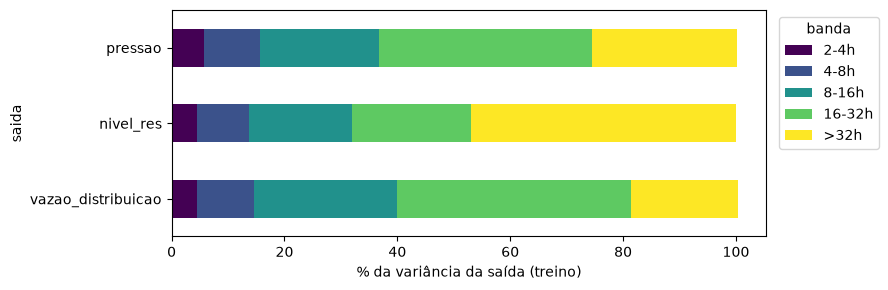

In [3]:
share = bands["var_%"].unstack().loc[OUTPUT_COLS, BANDS]
ax = share.plot.barh(stacked=True, figsize=(9, 3), colormap="viridis")
ax.set_xlabel("% da variância da saída (treino)")
ax.legend(title="banda", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG / "01_variancia_por_banda.png", dpi=150)

## Erro do baseline (C0) por banda

Validação, origens a cada 12h (série encadeada), média das 3 seeds. `erro/sinal` é a variância do erro na banda sobre a do sinal na banda.

In [4]:
def error_by_band(scenario: str, nivel: str) -> pd.DataFrame:
    rows = []
    for seed in (42, 43, 44):
        z = np.load(PREDS / f"C0_baseline_{scenario}_s{seed}.npz")
        y = z["val_true"][::12].reshape(-1, 3)
        p = z["val_pred"][::12].copy()
        if nivel == "cascata":
            p[..., 1] = z["val_nivel_cascata"][::12]
        p = p.reshape(-1, 3)
        for i, out in enumerate(OUTPUT_COLS):
            ce = atrous_components(y[:, i] - p[:, i], 4)[WARMUP:]
            cy = atrous_components(y[:, i], 4)[WARMUP:]
            err_total = (ce.sum(1) ** 2).mean()
            for k, band in enumerate(BANDS):
                rows.append({
                    "saida": out, "banda": band, "seed": seed,
                    "erro_%": 100 * ce[:, k].var() / ce.sum(1).var(),
                    "erro/sinal": ce[:, k].var() / cy[:, k].var(),
                    "mse_total": err_total,
                })
    return pd.DataFrame(rows).groupby(["saida", "banda"])[["erro_%", "erro/sinal"]].mean()

diag = {
    (scen, niv): error_by_band(scen, niv)
    for scen in ("full", "pumps")
    for niv in ("direto", "cascata")
}
pd.concat({f"{s}/{n}": d for (s, n), d in diag.items()}, axis=1).round(2)

full/direto            full/cascata             \
                               erro_% erro/sinal       erro_% erro/sinal   
saida              banda                                                   
nivel_res          16-32h       23.15       0.29        25.19       0.20   
                   2-4h          4.54       0.41         6.25       0.36   
                   4-8h          9.78       0.28         9.93       0.18   
                   8-16h        20.07       0.25        17.92       0.14   
                   >32h         43.04       0.59        34.37       0.30   
pressao            16-32h       12.58       0.03        12.58       0.03   
                   2-4h         24.00       0.52        24.00       0.52   
                   4-8h         23.01       0.26        23.01       0.26   
                   8-16h        21.57       0.11        21.57       0.11   
                   >32h         35.01       0.23        35.01       0.23   
vazao_distribuicao 16-32h       16.66       0.02        16.66       0.02   
                   2-4h         16.47       0.35        16.47       0.35   
                   4-8h         19.68       0.14        19.68       0.14   
                   8-16h        25.01       0.06        25.01       0.06   
                   >32h         22.87       0.07        22.87       0.07   

                          pumps/direto            pumps/cascata             
                                erro_% erro/sinal        erro_% erro/sinal  
saida              banda                                                    
nivel_res          16-32h        23.74       0.42         30.73       1.29  
                   2-4h           5.16       0.65          6.32       1.89  
                   4-8h          12.18       0.48         11.58       1.09  
                   8-16h         22.81       0.40         22.01       0.91  
                   >32h          36.68       0.70         22.18       1.00  
pressao            16-32h        12.56       0.03         12.56       0.03  
                   2-4h          22.54       0.50         22.54       0.50  
                   4-8h          22.65       0.26         22.65       0.26  
                   8-16h         21.71       0.11         21.71       0.11  
                   >32h          38.72       0.26         38.72       0.26  
vazao_distribuicao 16-32h        18.55       0.03         18.55       0.03  
                   2-4h          12.53       0.33         12.53       0.33  
                   4-8h          14.51       0.13         14.51       0.13  
                   8-16h         20.44       0.06         20.44       0.06  
                   >32h          39.45       0.16         39.45       0.16

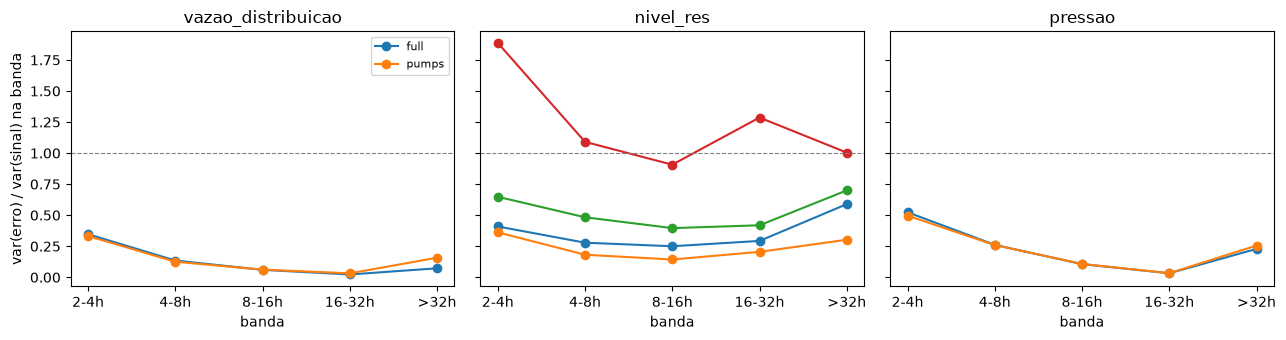

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, out in zip(axes, OUTPUT_COLS):
    for (scen, niv), d in diag.items():
        if out != "nivel_res" and niv == "cascata":
            continue
        ax.plot(BANDS, d.loc[out, "erro/sinal"].loc[BANDS], marker="o",
                label=f"{scen}" + (f" ({niv})" if out == "nivel_res" else ""))
    ax.axhline(1, color="grey", lw=0.8, ls="--")
    ax.set_title(out)
    ax.set_xlabel("banda")
axes[0].set_ylabel("var(erro) / var(sinal) na banda")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "02_erro_por_banda_baseline.png", dpi=150)

In [6]:
summary = {
    "bandas_treino": bands.round(4).reset_index().to_dict(orient="records"),
    "erro_baseline_val": {
        f"{s}/{n}": d.round(4).reset_index().to_dict(orient="records")
        for (s, n), d in diag.items()
    },
}
(PROJECT_ROOT / "outputs" / "decomposition_phase1.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False)
)

10765